# ACCESS-OM3 advection scheme variance production diagnostics

This notebook looks advection scheme variance production diagnostics to show spatial patterns and rates of numerical mixing.
The variance production diagnostics are new additions to MOM6 that track how grid cell variance changes due to advection.
In the continuous case, for a fluid parcel travelling with the flow there should be no material change due to advection and all moments of the tracer should be conserved.
Finite volume models ensure that the first moment (mean) is conserved but usually need to make a trade off between conserving higher order moments, like the variance, and smoothness ([Griffies et al. (2000)](https://journals.ametsoc.org/view/journals/mwre/128/3/1520-0493_2000_128_0538_sdmawa_2.0.co_2.xml).
We exploit this to track how advection schemes change grid cell variance giving us a grid cell metric that is a proxy for numerical mixing.
In the figures below negative variance production (variance destruction) is due to numerical diffusion while positive variance production is "un-mixing" which cannot occur in a real fluid but can occur due to numerical schemes.

This generated from the `00_template_notebook.ipynb` by Josef Bisits.

For more information about using intake-esm to find and load data, see:
- the [intake-esm documentation](https://intake-esm.readthedocs.io/en/stable/)
- [this section](https://access-nri-intake-catalog.readthedocs.io/en/latest/usage/quickstart.html#using-an-intake-esm-datastore) of the access-nri-intake-catalog documentation

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file = "/g/data/ol01/outputs/access-om3-100km/MC_100km_jra_iaf+wombatlite-test1-e1de2a94/experiment_datastore.json" # only experiment with these diags so far

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
if not papermill: 
    import nci_ipynb, os  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)

In [3]:
import xarray as xr
import cf_xarray
import intake
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import cmocean as cmo
from distributed import Client
import intake

In [4]:
client = Client(threads_per_worker=1)
print(client.dashboard_link)

/proxy/8787/status


In [5]:
IAF = esm_file.find('iaf') > 0
IAF

True

### Open the intake-esm datastore

In [6]:
COLUMNS_WITH_ITERABLES = [
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
]

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=COLUMNS_WITH_ITERABLES
)

### Check that the monthly advection scheme variance production diagnostics are there

In [7]:
def available_variables(datastore):
    """Return a pandas dataframe summarising the variables in a datastore"""
    variable_columns = [col for col in datastore.df.columns if "variable" in col]
    return (
        datastore.df[variable_columns]
        .explode(variable_columns)
        .drop_duplicates()
        .set_index("variable")
        .sort_index()
    )

In [8]:
T_asvp_name = "T_advection_scheme_variance_production"
S_asvp_name = "S_advection_scheme_variance_production"

T_check = datastore.search(realm="ocean", frequency="1mon", variable=T_asvp_name)
S_check = datastore.search(realm="ocean", frequency="1mon", variable=S_asvp_name)

available_variables(T_check)

,variable_long_name,variable_standard_name,variable_cell_methods,variable_units
variable,,,,
T_advection_scheme_variance_production,Spurious variance production of T variance due...,,area:mean zl:mean yh:mean xh:mean time: mean,Celsius2 m s-1
average_DT,Length of average period,,,days
average_T1,Start time for average period,,,days since 1900-01-01 00:00:00
average_T2,End time for average period,,,days since 1900-01-01 00:00:00
nv,vertex number,,,
time,time,,,days since 1900-01-01 00:00:00
time_bnds,time axis boundaries,,,days since 1900-01-01 00:00:00
xh,h point nominal longitude,,,degrees_east
yh,h point nominal latitude,,,degrees_north


### Load monthly advection scheme variance production for temperature

Here just produce a single monthly snapshot to check all looks reasonable.

In [10]:
T_asvp = datastore.search(variable=T_asvp_name, frequency="1mon").to_dask(
    xarray_combine_by_coords_kwargs = dict( # These kwargs can make things faster
        compat="override",
        data_vars="minimal",
        coords="minimal",
    ),
    xarray_open_kwargs = dict(
        chunks={"yh": -1, "xh": -1}, # Good for spatial operations, but not temporal
        decode_timedelta=True
    )
)
S_asvp = datastore.search(variable=S_asvp_name, frequency="1mon").to_dask(
    xarray_combine_by_coords_kwargs = dict( # These kwargs can make things faster
        compat="override",
        data_vars="minimal",
        coords="minimal",
    ),
    xarray_open_kwargs = dict(
        chunks={"yh": -1, "xh": -1}, # Good for spatial operations, but not temporal
        decode_timedelta=True
    )
)

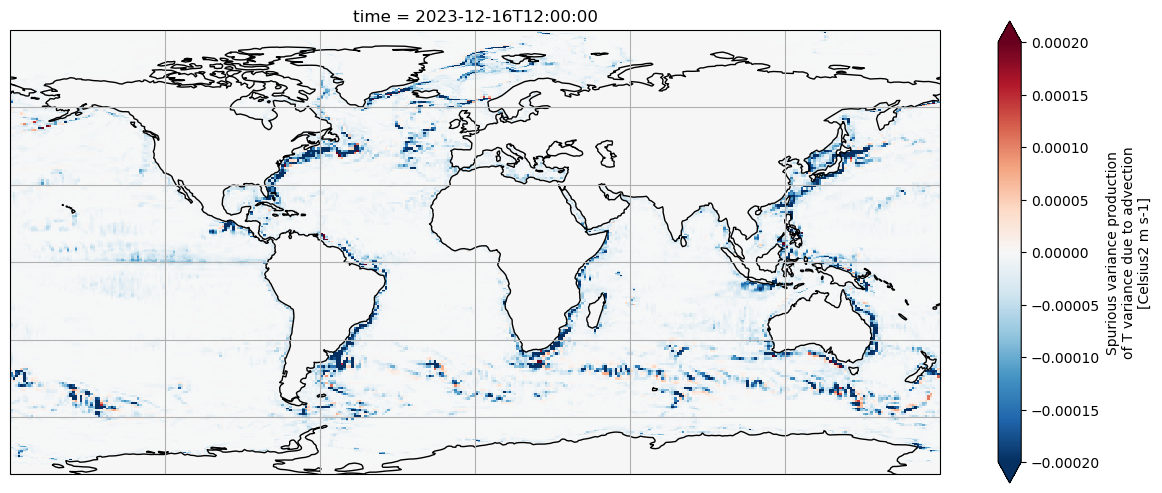

In [39]:
proj = ccrs.PlateCarree()
fig, ax = plt.subplots(figsize=(15,6), subplot_kw=dict(projection=proj))

T_asvp[T_asvp_name].sum(dim='zl').isel(time=-1).plot(ax=ax, vmin=-2e-4, vmax=2e-4, cmap="RdBu_r")
ax.coastlines()
_ = ax.gridlines()

#### Fixing the plot axes

Notice that the white land-masked regions are distorted away from the coastlines in the Arctic in the above plot. This is because a tripolar grid is used, so the grid lines are not zonal and meridional north of 65N, and consequently the nominal 1D coordinates `xh` and `yh` are incorrect. To fix this we need to use 2d coordinates `geolon` and `geolat`.

We can get these coorindates from the intake-esm datastore. However, note that in some cases `geolon` and `geolat` contain NaNs in regions where processors were masked over land. Below we replace these NaNs with zeros so that the coordinates can be used for plotting.

In [12]:
try:
# preferred source, if available (no processor masking holes)
# path is a workaround - see https://forum.access-hive.org.au/t/issues-in-loading-ht-in-latest-conds-envs/6278
    path = datastore.search(variable=["geolat", "geolon"], filename="access-om3.mom6.geometry.nc").df.loc[0, 'path']
    coords = datastore.search(variable=["geolat", "geolon"], path=path).to_dask().compute()
    coords = coords.rename({ "lonh": "xh", "lath": "yh" })
except:
# these contain NaNs in processor masks, so set NaNs to zero so they can be used for plotting
# path is a workaround - see https://forum.access-hive.org.au/t/issues-in-loading-ht-in-latest-conds-envs/6278
    path = datastore.search(variable=["geolat", "geolon"], filename="access-om3.mom6.static.nc").df.loc[0, 'path']
    coords = datastore.search(variable=["geolat", "geolon"], path=path).to_dask().compute()
    coords = coords.fillna(0.0)

T_asvp = T_asvp.assign_coords(coords)
S_asvp = S_asvp.assign_coords(coords)

## Time averaged depth and zonal integrals of variance production

### Temperature

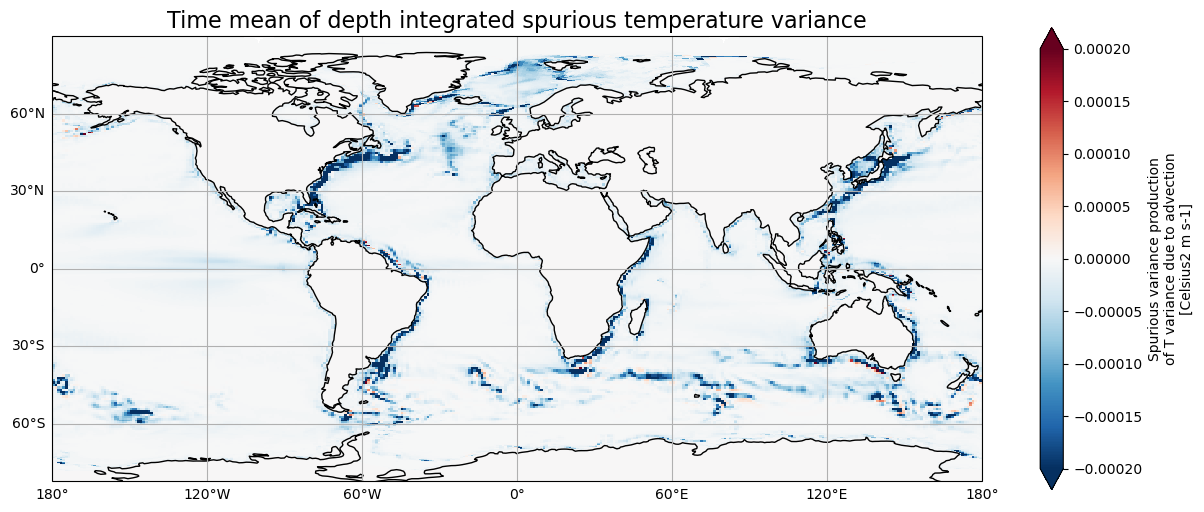

In [13]:
proj = ccrs.PlateCarree()
fig_temp, ax = plt.subplots(figsize=(15,6), subplot_kw=dict(projection=proj))

T_asvp[T_asvp_name].sum(dim='zl').mean(dim="time").plot(ax=ax, x="geolon", y="geolat", vmin=-2e-4, vmax=2e-4, cmap="RdBu_r")

ax.set_title("Time mean of depth integrated spurious temperature variance", fontsize=16)
ax.coastlines()
gl = ax.gridlines(draw_labels=True)
gl.top_labels=False
gl.right_labels=False

In [15]:
mkmd.savefig(fig_temp,"Numerical mixing notebook", "Time mean, depth integrated spurious variance prodcution of temperature", dpi=150)

The above figure is the time mean, depth integrated variance production.
Negative values, blues, indicate that temperature variance is being destroyed by the advection scheme (i.e. numerical mixing).
We see the most substantial variance destruction along western boundary currents and in the ACC which are energetic regions.
This agrees with [Holmes et al. (2021)](https://agupubs.onlinelibrary.wiley.com/doi/full/10.1029/2020MS002333).

Even with the time averaging there are still faint patches of red which are a production of variance (indicating "unmixing" which cannot happen in real fluids).
For our upcoming studies one of the last things is to look into whether or not this is a result of the advection scheme or the way the diagnostic isolates grid cell variance production.
But overall this figure is showing that laterally the advection scheme is destroying variance.

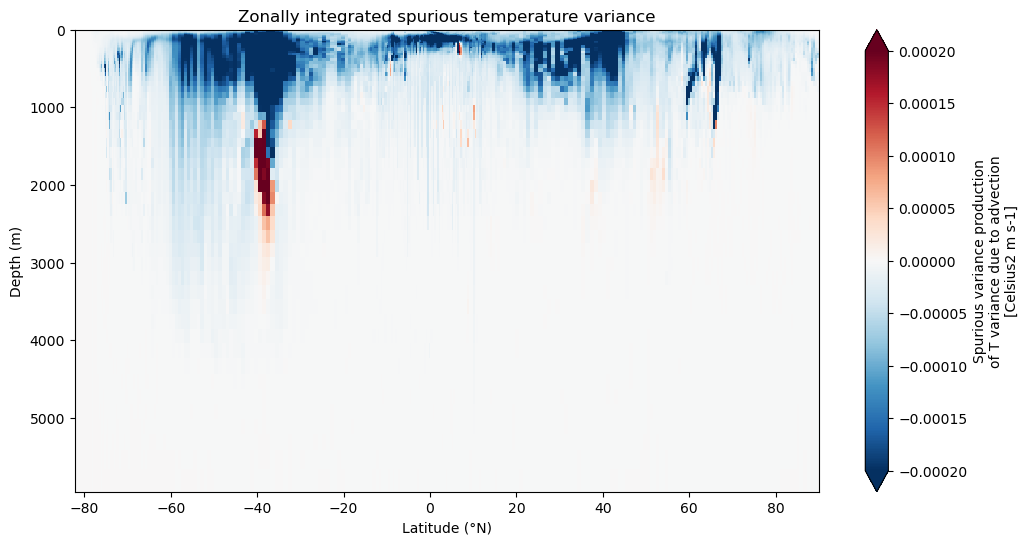

In [62]:
fig, ax = plt.subplots(figsize=(12, 6))

T_asvp[T_asvp_name].sum(dim="xh", skipna=True).mean(dim="time").plot(
    ax=ax,
    x="yh",
    y="zl",
    cmap="RdBu_r",
    vmin=-2e-4,
    vmax=2e-4,
)

ax.invert_yaxis()
ax.set_xlabel("Latitude (°N)")
ax.set_ylabel("Depth (m)")
ax.set_title("Zonally integrated spurious temperature variance")

plt.show()

The zonal mean shows a large patch of positive variance prodcution at depth.
This is something we have not seen in any ANU-TUB runs, could this be to do with bathymetry?
Apart from this, we again see that we have largely variance destruction and the majority of this occurs in the upper 1000m (on this colourscale).
The most affected latitudes are approximately $-60^{\circ}$N to $-30^{\circ}$N.
This is also seen in the depth integral where there are significant patches of variance destruction along the ACC.

### Salinity

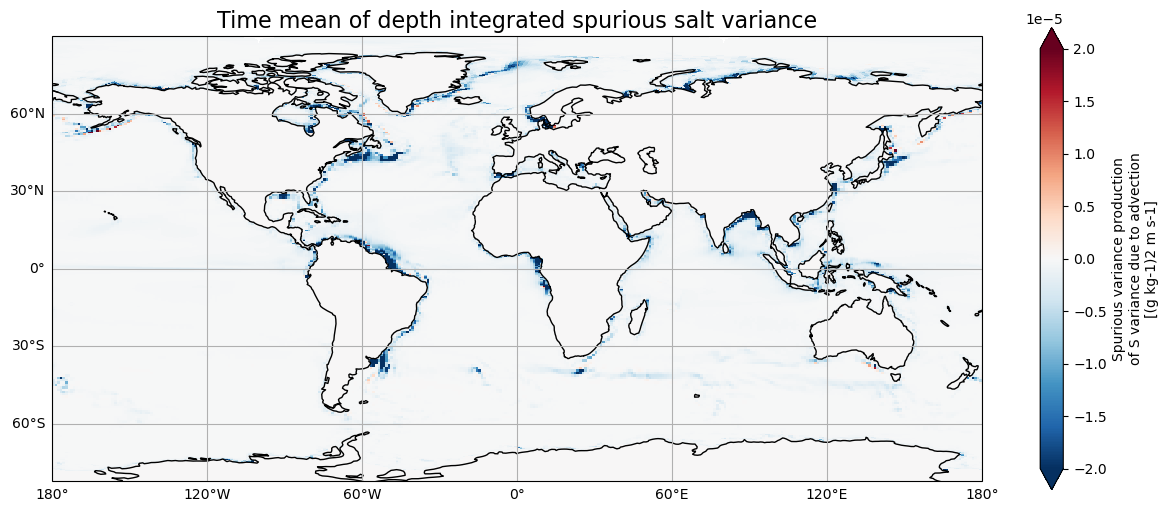

In [18]:
proj = ccrs.PlateCarree()
fig, ax = plt.subplots(figsize=(15,6), subplot_kw=dict(projection=proj))

S_asvp[S_asvp_name].sum(dim='zl').mean(dim="time").plot(ax=ax, x="geolon", y="geolat", vmin=-2e-5, vmax=2e-5, cmap="RdBu_r")

ax.set_title("Time mean of depth integrated spurious salt variance", fontsize=16)
ax.coastlines()
gl = ax.gridlines(draw_labels=True)
gl.top_labels=False
gl.right_labels=False

Significantly less variance destruction of salinity (the cbar is one orde of magnitude less than for temperature above).
Is this due to smaller lateral gradients?

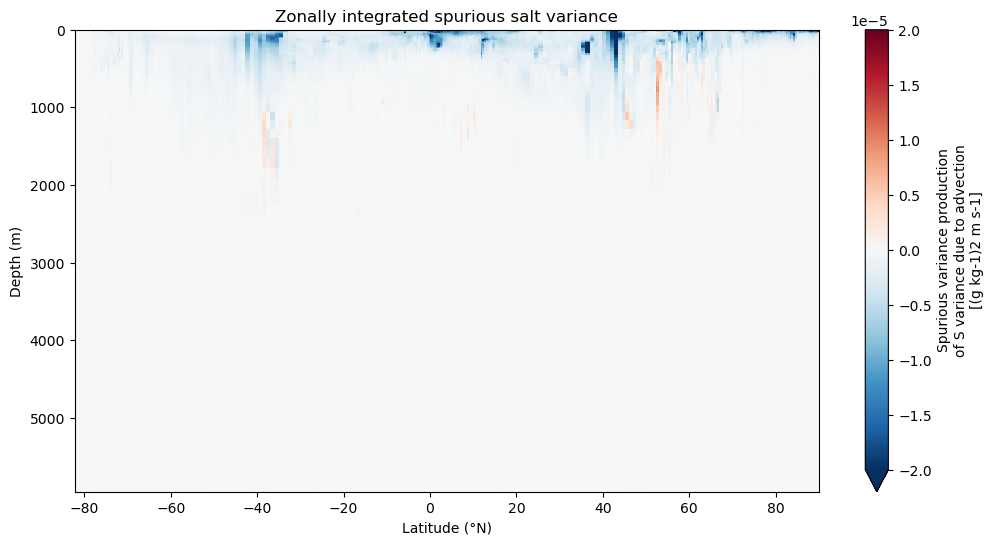

In [19]:
fig, ax = plt.subplots(figsize=(12, 6))

S_asvp[S_asvp_name].sum(dim="xh", skipna=True).mean(dim="time").plot(
    ax=ax,
    x="yh",
    y="zl",
    cmap="RdBu_r",
    vmin=-2e-5,
    vmax=2e-5,
)

ax.invert_yaxis()
ax.set_xlabel("Latitude (°N)")
ax.set_ylabel("Depth (m)")
ax.set_title("Zonally integrated spurious salt variance")

plt.show()

Again significantly lower rates!
I will need to look more into salt to further understand this.

### For diagnostics that will be run routinely on new OM3 output via papermill

Please include a key figure(s) or table(s) for output with the `mkfigs.sh` papermill workflow

In [13]:
# mkmd.savefig(title, caption, dpi=100)
# Save figure and append to markdown summary.
# title: title of figure
# caption: caption of figure
# dpi (optional; default: 100): dpi for figure
# mkmd.savefig(fig,"Template notebook", "Example figure of ACCESS-OM3 sea surface height (m).", dpi=150)

In [14]:
# mkmd.table(title, table)
# Append table to markdown summary.
# title: title of table
# table: markdown table strings (a list of strings where each string is a new line)
# mkmd.table("example title", available_variables(datastore_filtered).to_markdown().split('\n'))

In [15]:
client.close()